In [ ]:
# import packages
# import [] as [convention]
import pandas as pd # reading your csv, visualization, a lot of processing and data cleaning
import numpy as np # a lot of data manipulation, foundation for panda
import matplotlib.pyplot as plt # pyplot=subset of matplotlib, all sorts of graphs, not as pretty as R tho
import seaborn as sns # plots, a lot of overlap with matplotlib but can make specific types of plots like correlation heatmaps; correlation with one variable + all the other variables

In [ ]:
# mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# read the csvs from shared drive
env_df = pd.read_csv('/content/drive/Shareddrives/DDSC Data Pipeline/calenviroscreen-3.0-results-june-2018-update.csv')
inc_df = pd.read_csv('/content/drive/Shareddrives/DDSC Data Pipeline/incomedata_edited.csv')
  # Caleb 5/5: changed the URL to the edited csv

In [ ]:
# environmental data data exploration
env_df.head()


,Census Tract,Total Population,California County,ZIP,Nearby City \n(to help approximate location only),Longitude,Latitude,CES 3.0 Score,CES 3.0 Percentile,CES 3.0 \nPercentile Range,...,Linguistic Isolation Pctl,Poverty,Poverty Pctl,Unemployment,Unemployment Pctl,Housing Burden,Housing Burden Pctl,Pop. Char.,Pop. Char. Score,Pop. Char. Pctl
0,6019001100,3174,Fresno,93706,Fresno,-119.781696,36.709695,94.09,100.00,95-100% (highest scores),...,77.51,76.3,97.12,17.6,91.72,26.0,79.40,92.12,9.55,99.70
1,6071001600,6133,San Bernardino,91761,Ontario,-117.618013,34.057780,90.68,99.99,95-100% (highest scores),...,96.25,72.5,94.63,12.3,71.82,34.1,93.75,87.44,9.07,98.11
2,6019000200,3167,Fresno,93706,Fresno,-119.805504,36.735491,85.97,99.97,95-100% (highest scores),...,78.39,86.8,99.56,16.1,87.98,40.1,97.85,94.58,9.81,99.99
3,6077000801,6692,San Joaquin,95203,Stockton,-121.314524,37.940517,82.49,99.96,95-100% (highest scores),...,75.14,61.3,85.57,19.6,94.97,21.1,63.54,86.70,8.99,97.72
4,6019001500,2206,Fresno,93725,Fresno,-119.717843,36.681600,82.03,99.95,95-100% (highest scores),...,73.72,66.4,90.23,18.6,93.65,28.1,83.98,80.08,8.30,92.76


In [ ]:
# median income data data exploration
inc_df.head()

,County,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,Trinity County,6105,"53,498","2,457"
1,Siskiyou County,6093,"55,499","2,309"
2,Imperial County,6025,"56,393","2,246"
3,Modoc County,6049,"56,648","2,221"
4,Lake County,6033,"58,738","2,055"


In [ ]:
# get broad overview of data - how many missing values, data type of column
env_df.info()
inc_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 57 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Census Tract                                      8035 non-null   int64  
 1   Total Population                                  8035 non-null   int64  
 2   California County                                 8035 non-null   object 
 3   ZIP                                               8035 non-null   int64  
 4   Nearby City 
(to help approximate location only)  8035 non-null   object 
 5   Longitude                                         8035 non-null   float64
 6   Latitude                                          8035 non-null   float64
 7   CES 3.0 Score                                     7929 non-null   float64
 8    CES 3.0 Percentile                               7929 non-null   float64
 9   CES 3.0 
Percentile

In [ ]:
# DROP UNWANTED COLUMNS
df_coldrop = pd.DataFrame({'California County': env_df['California County'],
                           'Ozone': env_df['Ozone'], 'PM2.5': env_df['PM2.5'],
                           'Diesel PM': env_df['Diesel PM'],
                           'Drinking Water': env_df['Drinking Water'],
                           'Pesticides': env_df['Pesticides'],
                           'Tox. Release': env_df['Tox. Release'],
                           'Traffic': env_df['Traffic'],
                           'Cleanup Sites': env_df['Cleanup Sites'],
                           'Groundwater Threats': env_df['Groundwater Threats'],
                           'Haz. Waste': env_df['Haz. Waste'],
                           'Solid Waste': env_df['Solid Waste'],
                           'Pollution Burden': env_df['Pollution Burden'],
                           'Housing Burden': env_df['Housing Burden']}) # make new df with wanted columns
df_coldrop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   California County    8035 non-null   object 
 1   Ozone                8035 non-null   float64
 2   PM2.5                8016 non-null   float64
 3   Diesel PM            8035 non-null   float64
 4   Drinking Water       8017 non-null   float64
 5   Pesticides           8035 non-null   float64
 6   Tox. Release         8035 non-null   float64
 7   Traffic              7979 non-null   float64
 8   Cleanup Sites        8035 non-null   float64
 9   Groundwater Threats  8035 non-null   float64
 10  Haz. Waste           8035 non-null   float64
 11  Solid Waste          8035 non-null   float64
 12  Pollution Burden     8035 non-null   float64
 13  Housing Burden       7878 non-null   float64
dtypes: float64(13), object(1)
memory usage: 879.0+ KB


In [ ]:
# DROP ROWS with null housing burden
# (no need to drop null counties since the county column has 8035 non-nulls out of 8035 total entries)

# STEP 1: find all the rows where there is "nan" at the Housing Burden column
null_HB = []
for i in range(len(df_coldrop)):
  if (str(df_coldrop.loc[i]['Housing Burden']) == "nan"):
    null_HB.append(i)
print(f'Rows where the Housing Burden column has a value of nan: {null_HB}')


# STEP 2: Remove all rows identified by null_HB
rows_kept = [['California County', 'Ozone', 'PM2.5', 'Diesel PM', 'Drinking Water',
              'Pesticides', 'Tox. Release', 'Traffic', 'Cleanup Sites',
              'Groundwater Threats', 'Haz. Waste', 'Solid Waste', 'Pollution Burden',
              'Housing Burden']]
for i in range(len(df_coldrop)):
  if i not in null_HB:
   rows_kept.append(list(df_coldrop.loc[i]))
new_df = pd.DataFrame(rows_kept[1:], columns=rows_kept[0])


Rows where the Housing Burden column has a value of nan: [211, 273, 638, 813, 816, 1165, 1332, 1441, 1454, 1602, 1922, 2175, 2460, 2893, 3312, 3411, 3456, 3580, 3809, 3867, 4141, 4604, 4786, 4873, 4968, 4982, 5359, 5379, 5395, 5458, 5670, 5779, 5912, 5949, 5998, 6004, 6803, 6875, 6909, 7035, 7276, 7343, 7572, 7593, 7676, 7797, 7800, 7822, 7836, 7890, 7915, 7929, 7930, 7931, 7932, 7933, 7934, 7935, 7936, 7937, 7938, 7939, 7940, 7941, 7942, 7943, 7944, 7945, 7946, 7947, 7948, 7949, 7950, 7951, 7952, 7953, 7954, 7955, 7956, 7957, 7958, 7959, 7960, 7961, 7962, 7963, 7964, 7965, 7966, 7967, 7968, 7969, 7970, 7971, 7972, 7973, 7974, 7975, 7976, 7977, 7978, 7979, 7980, 7981, 7982, 7983, 7984, 7985, 7986, 7987, 7988, 7989, 7990, 7991, 7992, 7993, 7994, 7995, 7996, 7997, 7998, 7999, 8000, 8001, 8002, 8003, 8004, 8005, 8006, 8007, 8008, 8009, 8010, 8011, 8012, 8013, 8014, 8015, 8016, 8017, 8018, 8019, 8020, 8021, 8022, 8023, 8024, 8025, 8026, 8027, 8028, 8029, 8030, 8031, 8032, 8033, 8034]


In [27]:
# FIND MEDIANS for each county and FILL IN NULLS
env_cols=list(df_coldrop.columns[1:])
df=new_df.copy()

for county in df['California County'].unique():
  # STEP 1: Group by county
  county_data = []
  for i in range(len(df)):
    if str(df.loc[i]['California County']) == county:
      county_data.append(list(df.loc[i].values))
  county_df = pd.DataFrame(county_data, columns=rows_kept[0])

  # STEP 2: Find the median for each environmental predictor of that county
  for col in env_cols:
    median = county_df.loc[:,col].median()

  # STEP 3: fill in nulls
    for i in range(len(df)):
      if (df.loc[i]['California County'] == county) and (str(df.loc[i][col]) == "nan"):
        # print(f'Row {i}, {county} County, "{col}" Column: {df.loc[i][col]}')
        df.loc[i, col] = median
        # print(f'Row {i}, {county} County, "{col}" Column: {df.loc[i][col]}')

In [28]:
# DROP COUNTY NAME (since we found the county-column-specific medians and don't need them anymore)
final_df = df.drop('California County', axis=1)
final_df.head()

,Ozone,PM2.5,Diesel PM,Drinking Water,Pesticides,Tox. Release,Traffic,Cleanup Sites,Groundwater Threats,Haz. Waste,Solid Waste,Pollution Burden,Housing Burden
0,0.065,15.40,48.524,681.20,2.75,18551.957190,909.14,80.5,45.75,0.795,21.75,79.96,26.0
1,0.062,13.31,38.556,904.66,1.37,7494.236622,782.26,66.2,36.00,1.250,12.00,81.19,34.1
2,0.062,15.40,47.445,681.20,3.03,12454.948410,576.52,22.0,30.25,0.200,2.50,71.16,40.1
3,0.046,12.54,24.117,278.76,12.93,2387.782922,1305.01,50.1,132.10,0.795,27.00,74.48,21.1
4,0.065,15.40,18.846,1000.24,3518.41,21790.706720,435.16,60.0,54.20,13.100,50.80,80.20,28.1


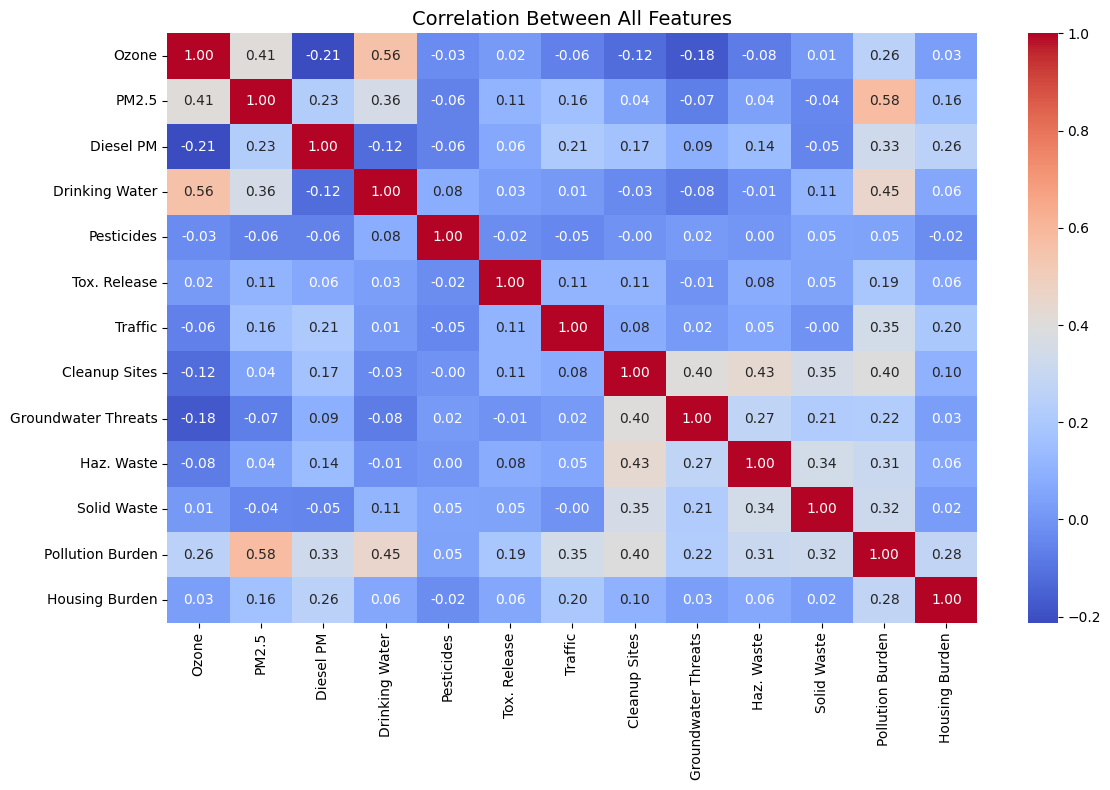

In [29]:
# correlation heatmap to show why these features were chosen for analysis
plt.figure(figsize=(12, 8))
sns.heatmap(final_df.corr(), annot=True, cmap='coolwarm', fmt='.2f') # 'df' should be the cleanest version!
plt.title("Correlation Between All Features", fontsize=14)
plt.tight_layout()

import os
os.makedirs('images', exist_ok=True)
plt.savefig('images/correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

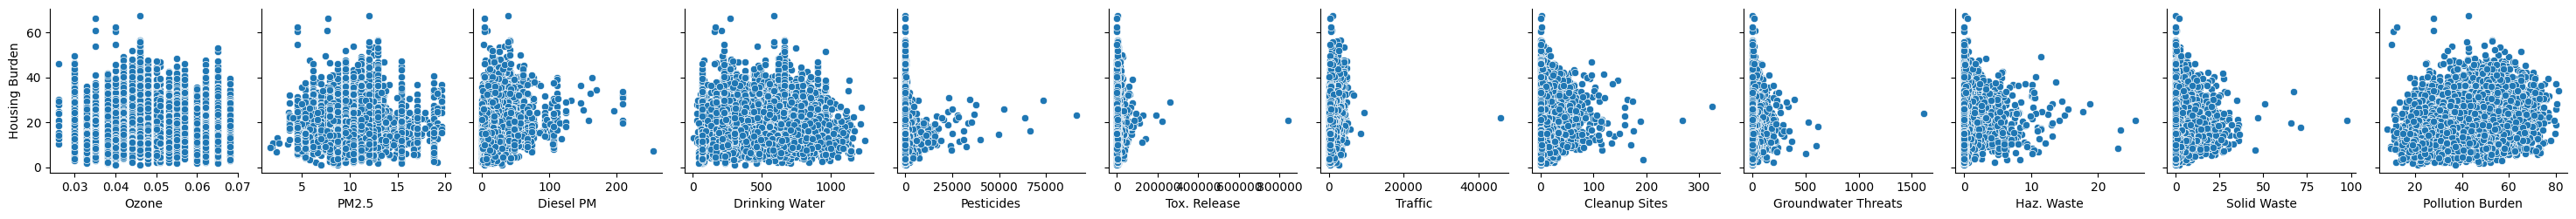

In [30]:
# plotting relationships between each variable and housing burden
pp = sns.pairplot(data=final_df,
                  y_vars=['Housing Burden'],
                  x_vars=['Ozone', 'PM2.5', 'Diesel PM', 'Drinking Water',
                          'Pesticides', 'Tox. Release', 'Traffic',
                          'Cleanup Sites', 'Groundwater Threats',
                          'Haz. Waste', 'Solid Waste', 'Pollution Burden'])

### Preparing Data for Machine Learning

First, we need to separate our features (independent variables) from our target variable ('Housing Burden'). Then, we'll split the data into training and testing sets. The training set will be used to teach the model, and the testing set will be used to evaluate how well the model generalizes to new, unseen data.

In [31]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = final_df.drop('Housing Burden', axis=1)
y = final_df['Housing Burden']

# Split the data into training and testing sets
# We'll use 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training features shape: (6302, 12)
Testing features shape: (1576, 12)
Training target shape: (6302,)
Testing target shape: (1576,)


In [32]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest Regressor model
# random_state for reproducibility
model = RandomForestRegressor(random_state=42)

# Train the model on the training data
model.fit(X_train, y_train)

print("Random Forest Regressor model trained successfully!")

Random Forest Regressor model trained successfully!


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse**0.5 # Root Mean Squared Error
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2 Score): {r2:.2f}")

Mean Absolute Error (MAE): 5.33
Mean Squared Error (MSE): 45.21
Root Mean Squared Error (RMSE): 6.72
R-squared (R2 Score): 0.38


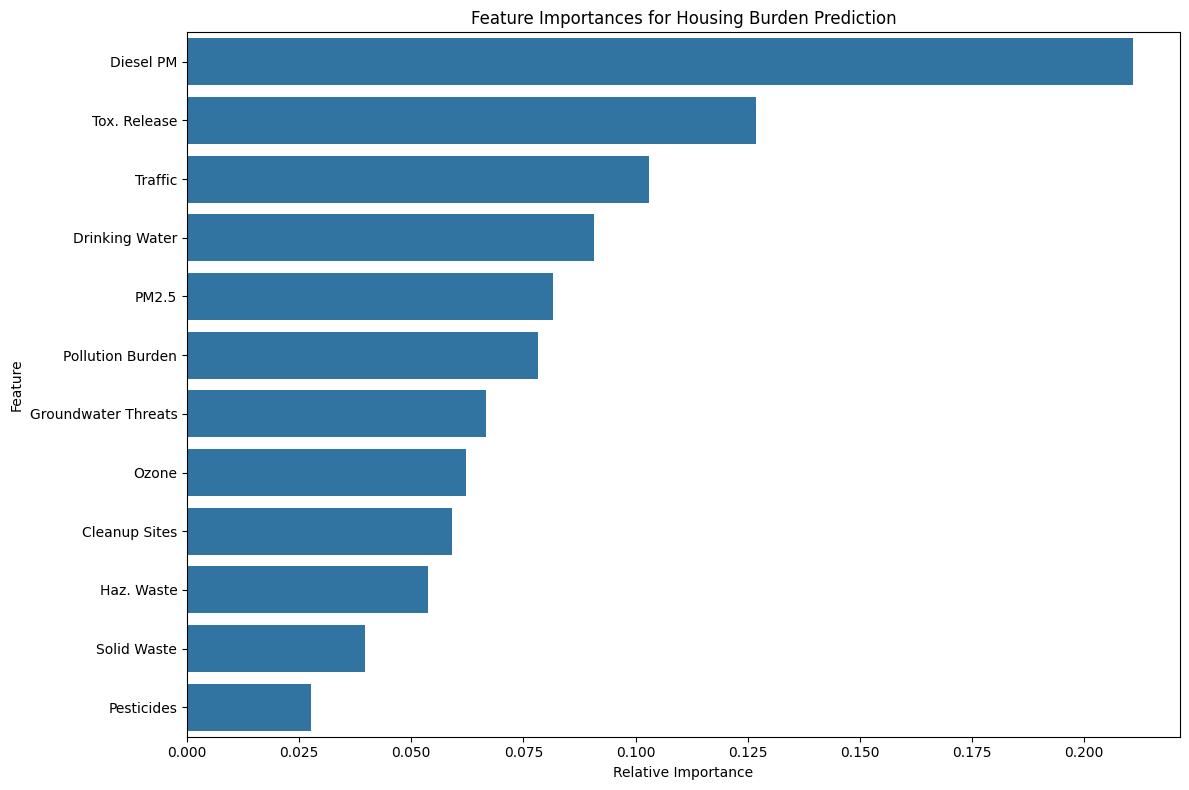

Top 5 most important features:
          Feature  Importance
2       Diesel PM    0.210840
5    Tox. Release    0.126760
6         Traffic    0.102947
3  Drinking Water    0.090808
1           PM2.5    0.081540


In [34]:
# Get feature importances from the trained model
feature_importances = model.feature_importances_

# Create a DataFrame for better visualization
features_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
})

# Sort features by importance in descending order
features_df = features_df.sort_values(by='Importance', ascending=False)

# Plotting feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=features_df)
plt.title('Feature Importances for Housing Burden Prediction')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("Top 5 most important features:")
print(features_df.head())